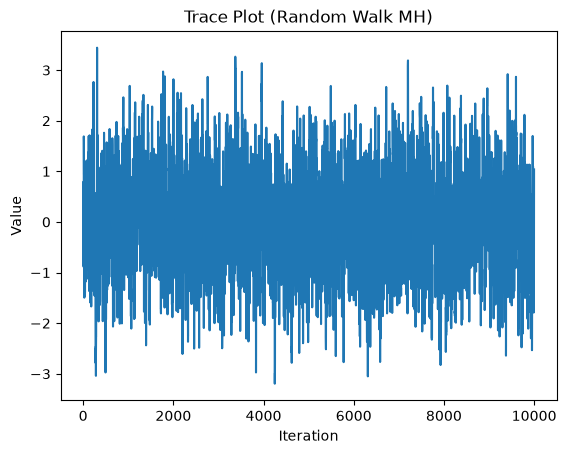

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

def target_pdf(x):
    return norm.pdf(x, 0, 1)

# Initialize
current_x = 0
samples = []
proposal_std = 1.0
n_iterations = 10000

for _ in range(n_iterations):
    # Propose a new state
    proposed_x = current_x + np.random.normal(0, proposal_std)
    
    # Acceptance ratio
    ratio = target_pdf(proposed_x) / target_pdf(current_x)
    
    # Accept or reject
    if np.random.rand() < ratio:
        current_x = proposed_x
        
    samples.append(current_x)

# Plot the trace
plt.plot(samples)
plt.title("Trace Plot (Random Walk MH)")
plt.xlabel("Iteration")
plt.ylabel("Value")
plt.show()

In [2]:
from scipy.stats import beta

# Data: 8 successes, 4 failures (total 12 trials)
# Beta(2,2) prior -> Posterior is Beta(2+8, 2+4) = Beta(10, 6)

# Sample from the posterior distribution
posterior_samples = beta.rvs(10, 6, size=10000)

print(f"Posterior Mean: {np.mean(posterior_samples):.4f}")
print(f"95% Credible Interval: [{np.percentile(posterior_samples, 2.5):.4f}, {np.percentile(posterior_samples, 97.5):.4f}]")

Posterior Mean: 0.6268
95% Credible Interval: [0.3806, 0.8388]


**Q3: MCMC Diagnostics**

* **Trace Plots:** Show the sampled values at each iteration. A well-mixed chain looks like "white noise" (a fuzzy caterpillar) without an upward or downward trend. It shows if the chain is exploring the whole parameter space.
* **ACF (Autocorrelation Function):** Measures the correlation between a sample and its lagged values (e.g., how correlated a sample is with the one 5 steps before it). It should drop to zero quickly. High autocorrelation means the chain is moving very slowly and taking a long time to explore the space.
* **R-hat (Gelman-Rubin statistic):** Compares the variance *between* multiple independent chains to the variance *within* each chain. It should be close to 1.0 (ideally < 1.01). Values > 1.05 indicate that the chains have not converged to the same distribution.
* **ESS (Effective Sample Size):** Because MCMC samples are autocorrelated, 10,000 raw samples are not as good as 10,000 independent samples. ESS estimates the equivalent number of independent samples. You want a large ESS (e.g., > 400) for reliable posterior estimates.

g++ not available, if using conda: `conda install gxx`
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (2 chains in 2 jobs)
NUTS: [mu, sigma]


c:\Users\Aphilox\anaconda3\envs\ICD341\Lib\site-packages\rich\live.py:260: UserWarning: install "ipywidgets" for 
Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 15 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics


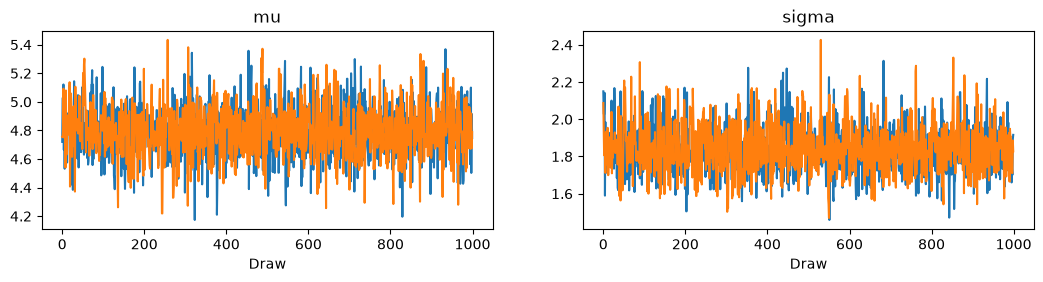

In [3]:
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt

# Generate some fake data
np.random.seed(42)
y_obs = np.random.normal(loc=5, scale=2, size=100)

with pm.Model() as normal_model:
    # Priors
    mu = pm.Normal('mu', mu=0, sigma=10)
    sigma = pm.HalfNormal('sigma', sigma=5)
    
    # Likelihood
    y = pm.Normal('y', mu=mu, sigma=sigma, observed=y_obs)
    
    # Sampling
    trace = pm.sample(1000, return_inferencedata=True)

# Plot the trace
az.plot_trace(trace)
plt.show()